### Employee Wellness Interventions: Statistical Analysis and Machine Learning
Employee satisfaction, engagement, and retention are critical factors in organizational performance. This project analyzes employee wellness data from BSR to examine how workplace interventions for sleep, exercise, and smoking cessation are associated with changes in employee outcomes.

I used Python for this project for exploratory data analysis, data visualization, hypothesis testing, and machine learning to investigate the relationships between wellness interventions and employee behavior.


Tools and Methods

Python | Pandas | NumPy | Matplotlib | Seaborn | SciPy | Scikit-learn



Data prepping


In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import PrecisionRecallDisplay
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
from sklearn.model_selection import validation_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from scipy import stats
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import clone

In [91]:
from google.colab import files

uploaded = files.upload()

Saving BSR Data Set 2026.xlsx to BSR Data Set 2026 (2).xlsx


In [92]:
df = pd.read_excel('BSR Data Set 2026.xlsx', index_col=0)

In [93]:
df.head()

,Last_name,Gender,Employee ID,Children (Y/N),Race,Office Location,Employee Level,Employee Job Family,Start Date,Tenure (Years),...,Pre Engagement question 3,Pre Satisfaction question 1,Pre Satisfaction question 2,Pre Satisfaction question 3,Post Engagement question 1,Post Engagement question 2,Post Engagement question 3,Post Satisfaction question 1,Post Satisfaction question 2,Post Satisfaction question 3
First_name,,,,,,,,,,,,,,,,,,,,,
Don,Aaronsohn,Male,Aa7Do4,Y,White,CO,Junior,Accounting and Finance,2023-05-16,1.501370,...,2,3,4,4,1,1,1,4,5,5
Biddie,A'Barrow,Female,Ab1Bi3,N,White,CO,Junior,Customer Service,2016-11-06,8.030137,...,1,4,5,5,4,1,1,5,5,5
Theresa,Abbatini,Female,Ab1Th9,N,Hispanic,CO,Junior,Customer Service,2023-01-16,1.830137,...,1,4,3,4,4,2,1,5,4,5
Ferris,Abbots,Male,Ab7Fe3,Y,White,CO,Junior,Administrative,2019-08-21,5.238356,...,1,3,3,3,3,4,4,4,4,4
Korry,Acosta,Female,Ac2Ko0,N,Hispanic,IL,Junior,Customer Service,2015-08-22,9.238356,...,2,3,3,3,1,3,3,4,4,4


In [94]:
df.tail()

,Last_name,Gender,Employee ID,Children (Y/N),Race,Office Location,Employee Level,Employee Job Family,Start Date,Tenure (Years),...,Pre Engagement question 3,Pre Satisfaction question 1,Pre Satisfaction question 2,Pre Satisfaction question 3,Post Engagement question 1,Post Engagement question 2,Post Engagement question 3,Post Satisfaction question 1,Post Satisfaction question 2,Post Satisfaction question 3
First_name,,,,,,,,,,,,,,,,,,,,,
Cchaddie,Zhuang,Male,Zh8Cc0,N,Asian,MN,Junior,Accounting and Finance,2021-06-15,3.419178,...,4,3,4,3,5,5,4,4,5,4
Bruno,Zhuang,Male,Zh0Br3,Y,Asian,CO,Junior,Accounting and Finance,2020-05-27,4.473973,...,5,3,3,3,1,3,5,4,4,4
Fancie,Zieme,Female,Zi3Fa5,Y,White,UT,Manager,Administrative,2020-09-05,4.197260,...,5,4,4,4,5,5,5,5,5,5
Lynsey,Zorzini,Female,Zo6Ly4,N,White,UT,Junior,Administrative,2023-05-06,1.528767,...,1,3,3,5,5,5,5,4,4,5
Kira,Zupa,Female,Zu4Ki0,N,White,UT,Junior,Customer Service,2020-09-01,4.208219,...,2,3,3,3,1,2,2,5,4,4


In [95]:
df.describe()

,Start Date,Tenure (Years),Salary,Age,Distance from home to office (Miles) if not remote,Average commute (minutes) if not remote,Change readiness 1 (1-5),Change readiness 2 (1-5),Change readiness 3 (1-5),Change readiness 4 (1-5),...,Pre Engagement question 3,Pre Satisfaction question 1,Pre Satisfaction question 2,Pre Satisfaction question 3,Post Engagement question 1,Post Engagement question 2,Post Engagement question 3,Post Satisfaction question 1,Post Satisfaction question 2,Post Satisfaction question 3
count,1500,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,...,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,2019-09-04 10:20:09.600000,5.199286,81954.523196,30.012606,18.375965,22.904000,2.733333,2.733333,2.854667,2.914000,...,2.360667,3.844000,3.860000,3.852000,2.774000,2.768667,2.772667,4.519333,4.348000,4.340667
min,2000-01-30 00:00:00,1.117808,34804.980000,19.121765,0.208916,8.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,2.000000,3.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000
25%,2018-04-21 12:00:00,2.410274,43483.037911,24.994819,10.875784,15.000000,2.000000,2.000000,2.000000,2.000000,...,1.000000,3.000000,3.000000,3.000000,1.000000,1.000000,1.000000,4.000000,4.000000,4.000000
50%,2020-12-12 12:00:00,3.927397,56900.056500,28.261441,18.653344,23.000000,3.000000,3.000000,3.000000,3.000000,...,2.000000,4.000000,4.000000,4.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
75%,2022-06-18 06:00:00,6.571233,74822.737500,32.000000,25.882948,31.000000,3.000000,3.000000,3.000000,4.000000,...,3.000000,5.000000,5.000000,5.000000,4.000000,4.000000,4.000000,5.000000,5.000000,5.000000
max,2023-10-03 00:00:00,24.808219,506222.640000,60.478948,36.858017,38.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
std,NaN,3.971523,74112.588921,7.910290,8.801847,8.612795,1.111326,1.117313,1.071281,1.176801,...,1.400914,0.876457,0.863847,0.863284,1.510997,1.508864,1.515206,0.711311,0.754061,0.762234


In [96]:
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape: (1500, 56)
Missing values: 0
Duplicate rows: 0


No nulls or missing values so no need to drop or impute values

Concludes data prepping process, so there are 1500 rows of data

In [97]:
df['Change Readiness'] = df[
    [f'Change readiness {i} (1-5)' for i in range(1, 6)]
].mean(axis=1)

df['Change Commitment'] = df[
    [f'Change commitment {i} (1-5)' for i in range(1, 6)]
].mean(axis=1)

df['Engagement'] = df[
    [f'Pre Engagement question {i}' for i in range(1, 4)]
].mean(axis=1)

df['Satisfaction'] = df[
    [f'Pre Satisfaction question {i}' for i in range(1, 4)]
].mean(axis=1)

df['Intention to Stay'] = df['Pre: Intention to Stay']

In [98]:
# Pre-intervention
df['Pre Engagement'] = df[
    [f'Pre Engagement question {i}' for i in range(1, 4)]
].mean(axis=1)

df['Pre Satisfaction'] = df[
    [f'Pre Satisfaction question {i}' for i in range(1, 4)]
].mean(axis=1)

# Post-intervention
df['Post Engagement'] = df[
    [f'Post Engagement question {i}' for i in range(1, 4)]
].mean(axis=1)

df['Post Satisfaction'] = df[
    [f'Post Satisfaction question {i}' for i in range(1, 4)]
].mean(axis=1)

# Intention to stay
df['Pre Stay'] = df['Pre: Intention to Stay']
df['Post Stay'] = df['Post: Intention to Stay']

In [99]:
df['Engagement Change'] = df['Post Engagement'] - df['Pre Engagement']
df['Satisfaction Change'] = df['Post Satisfaction'] - df['Pre Satisfaction']
df['Stay Change'] = df['Post Stay'] - df['Pre Stay']

In [100]:
age_bin = [15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, np.inf]

range_names = ['16-20', '21-25', '26-30', '31-35', '36-40',
               '41-45', '46-50', '51-55', '56-60', '61-65', '66+']

df['age_range'] = pd.cut(df['Age'], bins=age_bin, labels=range_names)

In [101]:
tenure_bins = [0, 5, 10, 15, 20, 25, 30, np.inf]

tenure_labels = ['0-5', '6-10', '11-15', '16-20',
                 '21-25', '26-30', '31+']

df['tenure_range'] = pd.cut(
    df['Tenure (Years)'],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True)

Exploring and visualizing data demographics

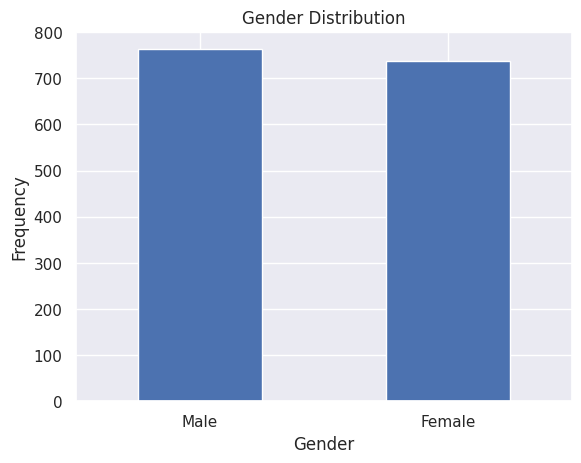

In [102]:
df["Gender"].value_counts().plot(kind="bar")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Frequency")
plt.xticks(rotation=0)
plt.show()

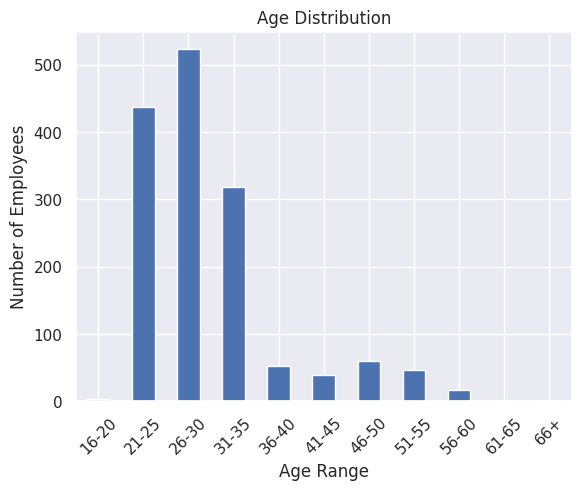

In [103]:
df['age_range'].value_counts().sort_index().plot(kind='bar')

plt.title("Age Distribution")
plt.xlabel("Age Range")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.show()

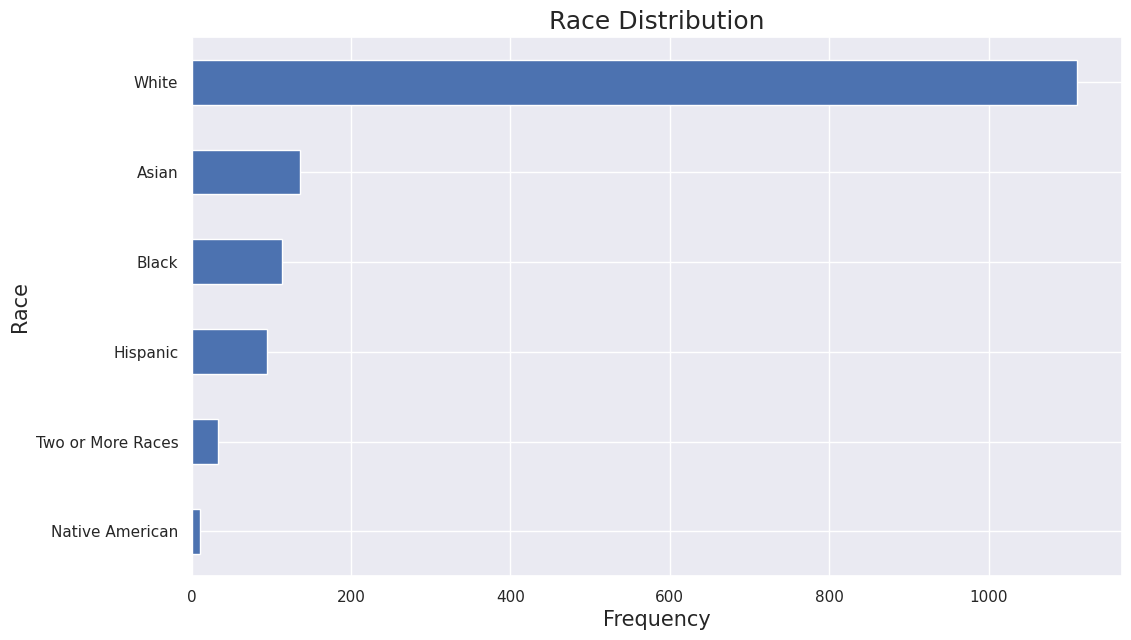

In [104]:
fig = plt.figure(figsize=(12, 7))

ax = df['Race'].value_counts().plot(kind='barh')

plt.gca().invert_yaxis()
plt.title("Race Distribution", fontsize=18)
plt.xlabel("Frequency", fontsize=15)
plt.ylabel("Race", fontsize=15)

plt.show()

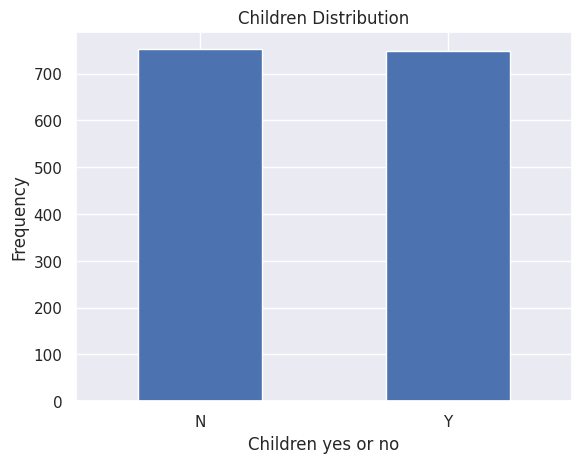

In [105]:
df["Children (Y/N)"].value_counts().plot(kind="bar")

plt.title("Children Distribution")
plt.xlabel("Children yes or no")
plt.ylabel("Frequency")
plt.xticks(rotation=0)
plt.show()

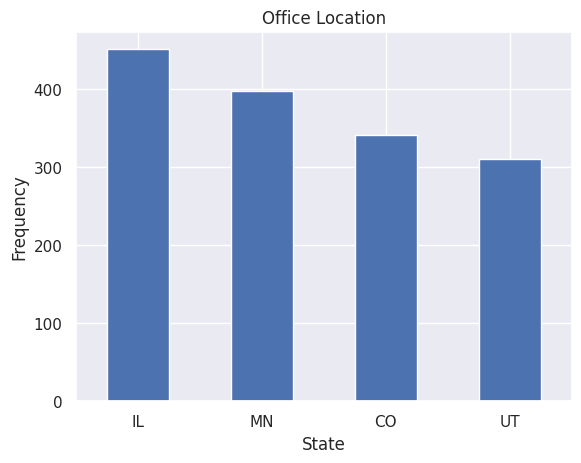

In [106]:
df["Office Location"].value_counts().plot(kind="bar")

plt.title("Office Location")
plt.xlabel("State")
plt.ylabel("Frequency")
plt.xticks(rotation=0)
plt.show()

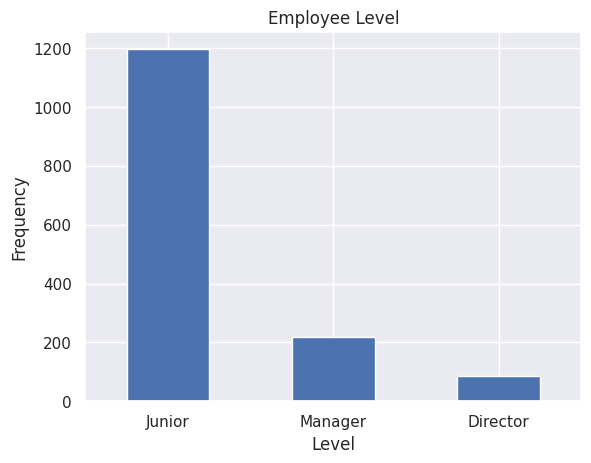

In [107]:
df["Employee Level"].value_counts().plot(kind="bar")

plt.title("Employee Level")
plt.xlabel("Level")
plt.ylabel("Frequency")
plt.xticks(rotation=0)
plt.show()

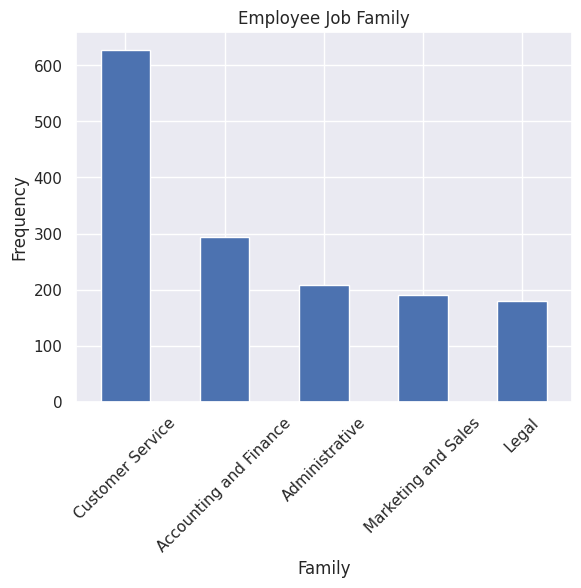

In [108]:
df["Employee Job Family"].value_counts().plot(kind="bar")

plt.title("Employee Job Family")
plt.xlabel("Family")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.show()

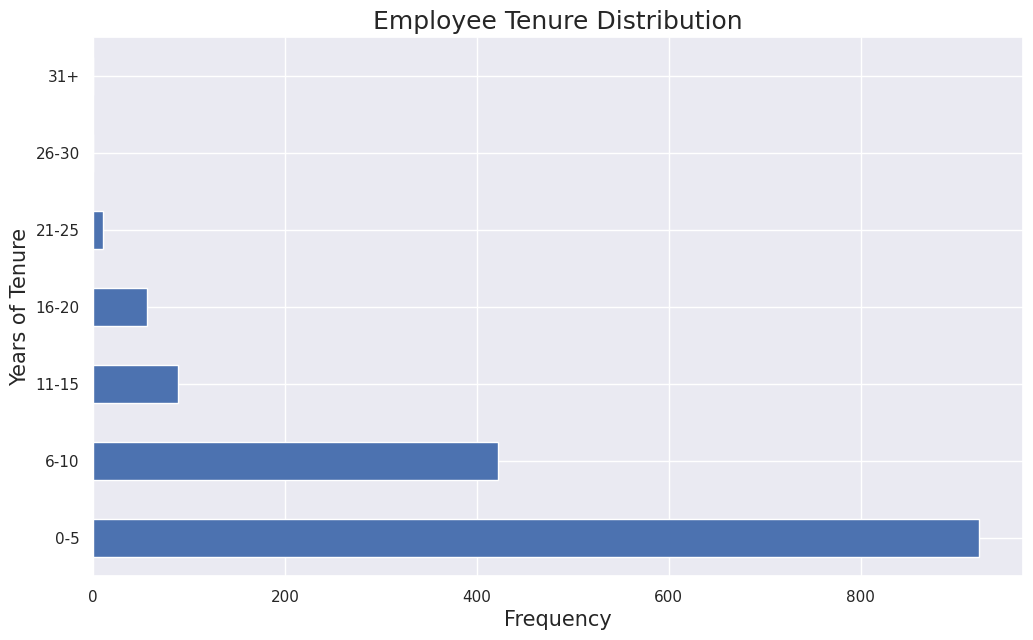

In [109]:
fig = plt.figure(figsize=(12, 7))

ax = df['tenure_range'].value_counts().sort_index().plot(kind='barh')

plt.title("Employee Tenure Distribution", fontsize=18)
plt.xlabel("Frequency", fontsize=15)
plt.ylabel("Years of Tenure", fontsize=15)

plt.show()

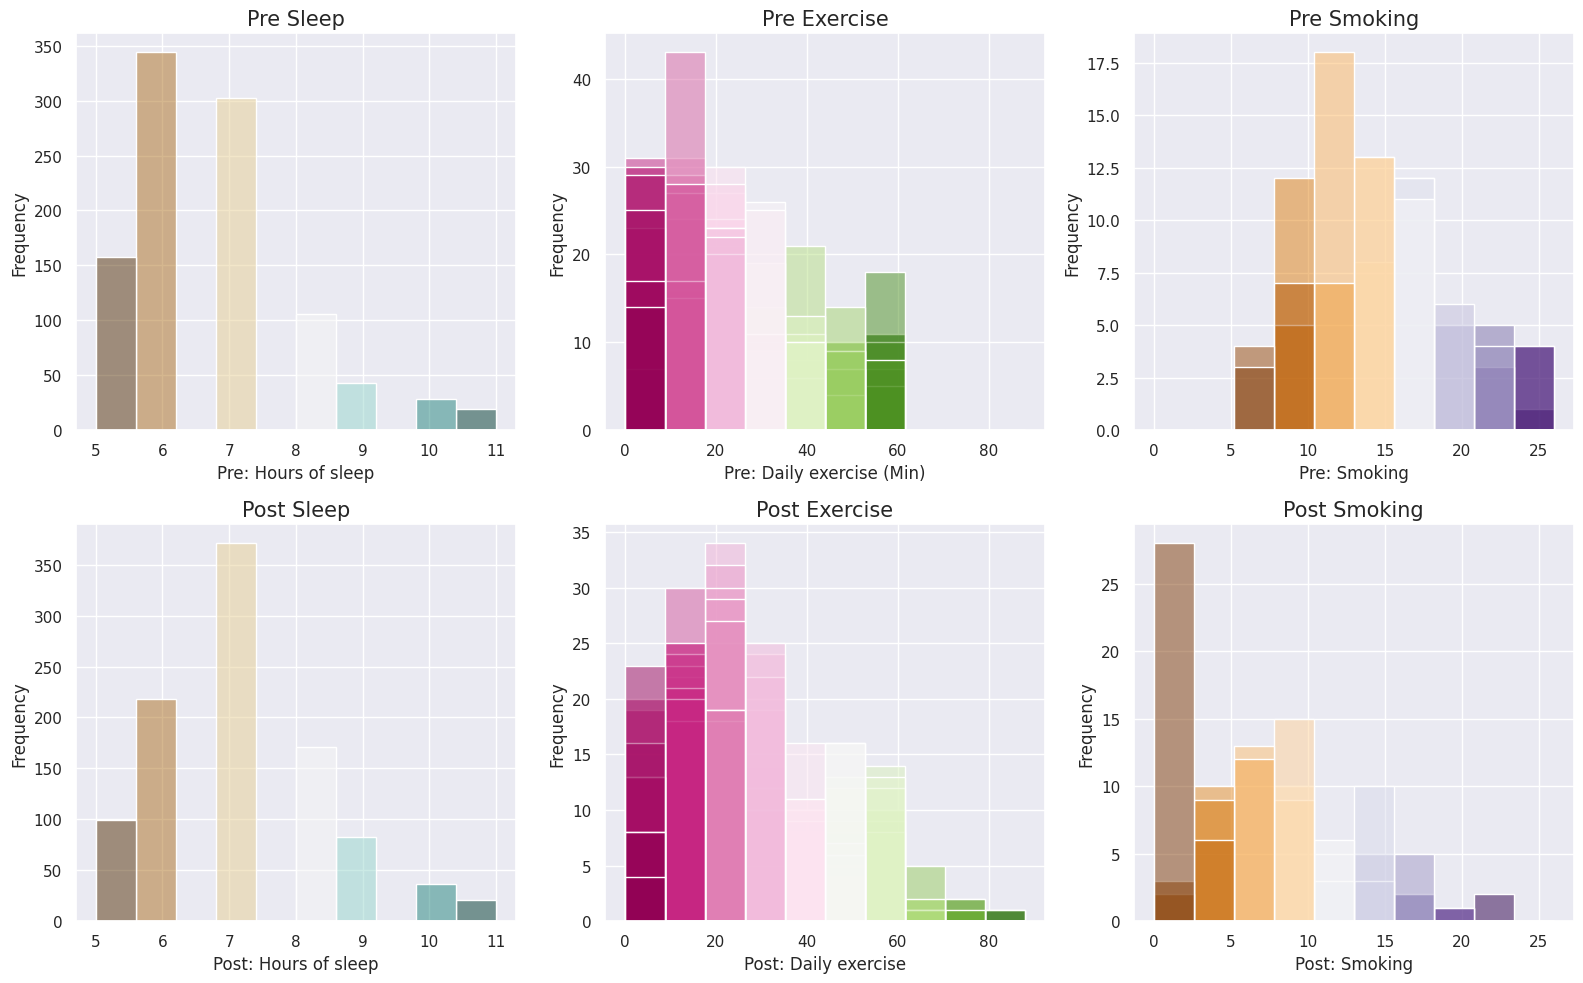

In [110]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

interventions = [
    ('Sleep intervention (Y=1, N=0)',
     'Pre: Hours of sleep', 'Post: Hours of sleep', 'Sleep'),

    ('Exercise intervention (Y=1, N=0)',
     'Pre: Daily exercise (Min)', 'Post: Daily exercise', 'Exercise'),

    ('Smoking intervention (Y=1,N=0)',
     'Pre: Smoking', 'Post: Smoking', 'Smoking')
]

palettes = ['BrBG', 'PiYG', 'PuOr']

for i, (intervention, pre, post, title) in enumerate(interventions):

    # Only employees who received the intervention
    group = df[df[intervention] == 1]

    # Use the same bins for pre and post
    bins = np.histogram_bin_edges(
        pd.concat([group[pre], group[post]]).dropna(),
        bins=10
    )

    for row, variable in enumerate([pre, post]):
        ax = axes[row, i]

        sns.histplot(
            data=group,
            x=variable,
            bins=bins,
            hue=variable,
            palette=palettes[i],
            legend=False,
            ax=ax
        )

        period = "Pre" if row == 0 else "Post"
        ax.set_title(f"{period} {title}", fontsize=15)
        ax.set_xlabel(variable)
        ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

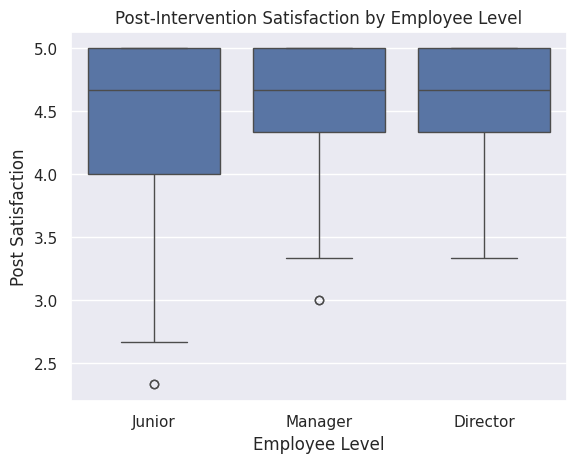

In [111]:
sns.boxplot(
    data=df,
    x='Employee Level',
    y='Post Satisfaction'
)

plt.title("Post-Intervention Satisfaction by Employee Level")
plt.show()

/tmp/ipykernel_447/2252021746.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 95)` for the same effect.

  sns.barplot(


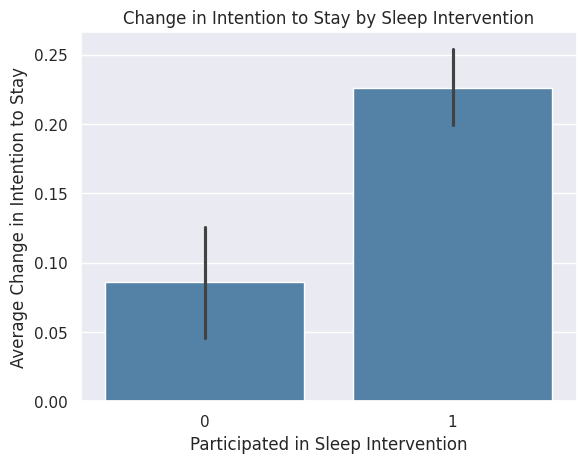

In [112]:
sns.barplot(
    data=df,
    x='Sleep intervention (Y=1, N=0)',
    y='Stay Change',
    ci=95,
    color="steelblue"
)

plt.title("Change in Intention to Stay by Sleep Intervention")
plt.xlabel("Participated in Sleep Intervention")
plt.ylabel("Average Change in Intention to Stay")
plt.show()

- Sleep Intervention: Participants improved substantially more than nonparticipants in engagement (+0.619) and satisfaction (+0.684). Intention to stay also improved slightly more (+0.140).
- Exercise Intervention: Participants improved less in engagement (-0.182) but slightly more in satisfaction (+0.123) and intention to stay (+0.150).
- Smoking Intervention: Participants experienced the largest relative improvement in engagement (+0.984). However, there was almost no difference in intention-to-stay changes (+0.006).

The graphs showcase that:
- Gender: Relatively similar with slightly more male employees
- Age: 26-30 is the highest age group with over 500 employees, followed by 21-25 and 31-35 age groups.
- Race: a majority of employees are white, making up over a 1000 employees at the company. Asian, Black, and Hispanic employees make up under 200 employees each.
- Children: distribution of employees with and without children is relatively even, with slightly more people not having children.
- Office Location: the order of most to least populous states are Illinois, Minnesota, Colorado, and Utah.
- Employee level: most employees are at the junior levels and the fewest employees are at the director level.
- Employee job family: Customer service has the highest number of employees and legal has the least.
- Tenure: Most employees have been at BSR for 0-5 years or 6-10 years.  


Exploring and visualizing

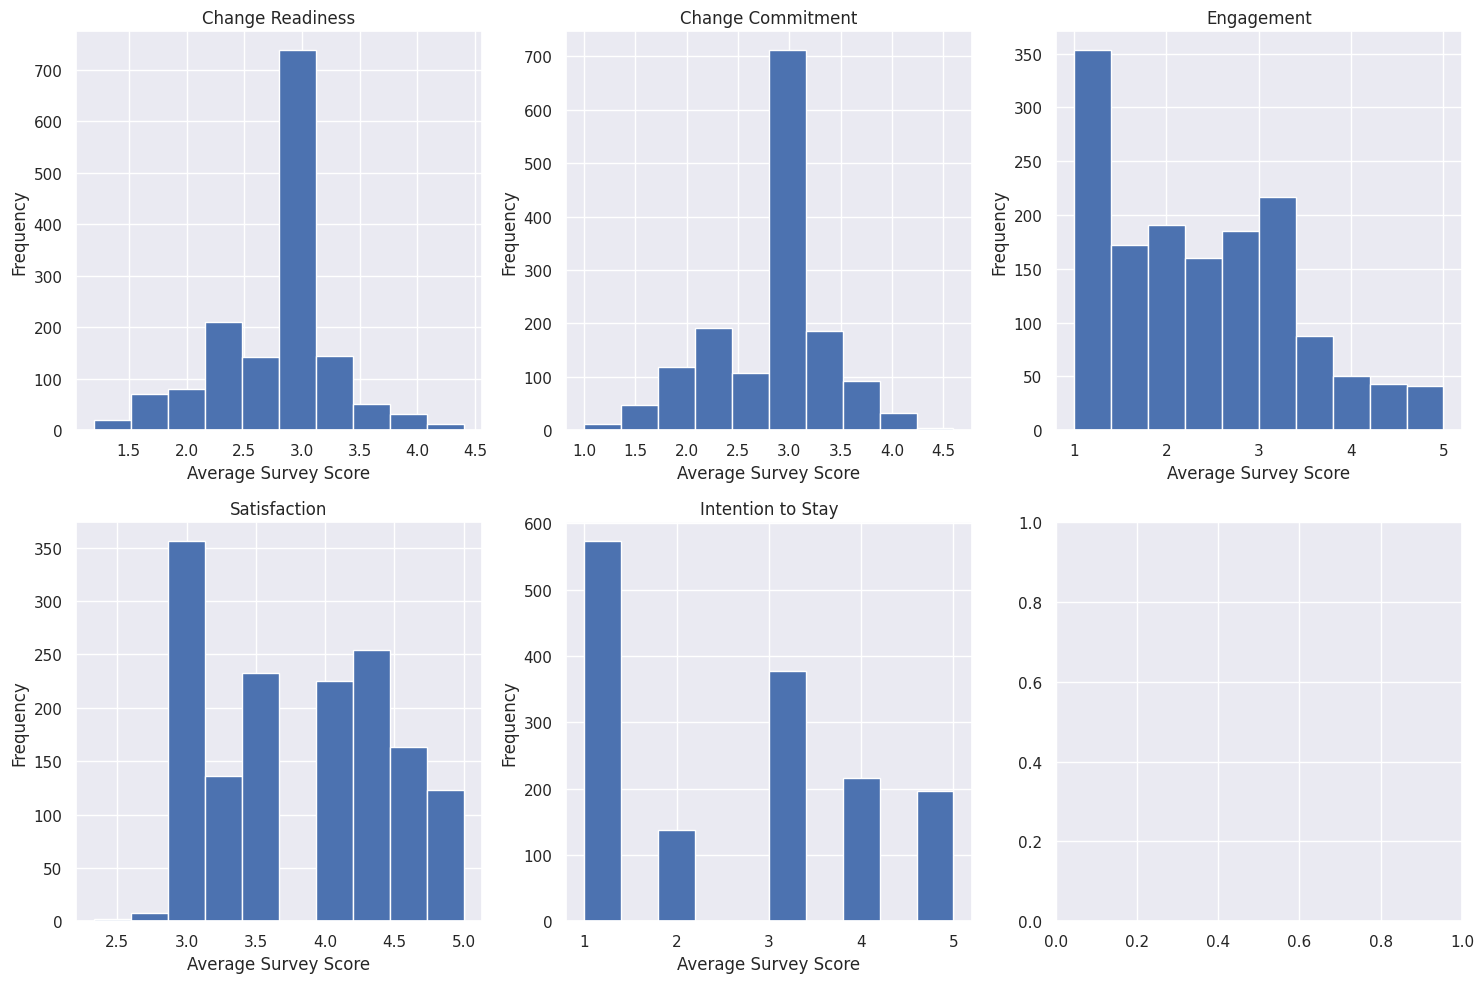

In [113]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

variables = [
    'Change Readiness',
    'Change Commitment',
    'Engagement',
    'Satisfaction',
    'Intention to Stay'
]

for ax, variable in zip(axes.flat, variables):
    df[variable].plot(kind='hist', bins=10, ax=ax)
    ax.set_title(variable)
    ax.set_xlabel("Average Survey Score")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

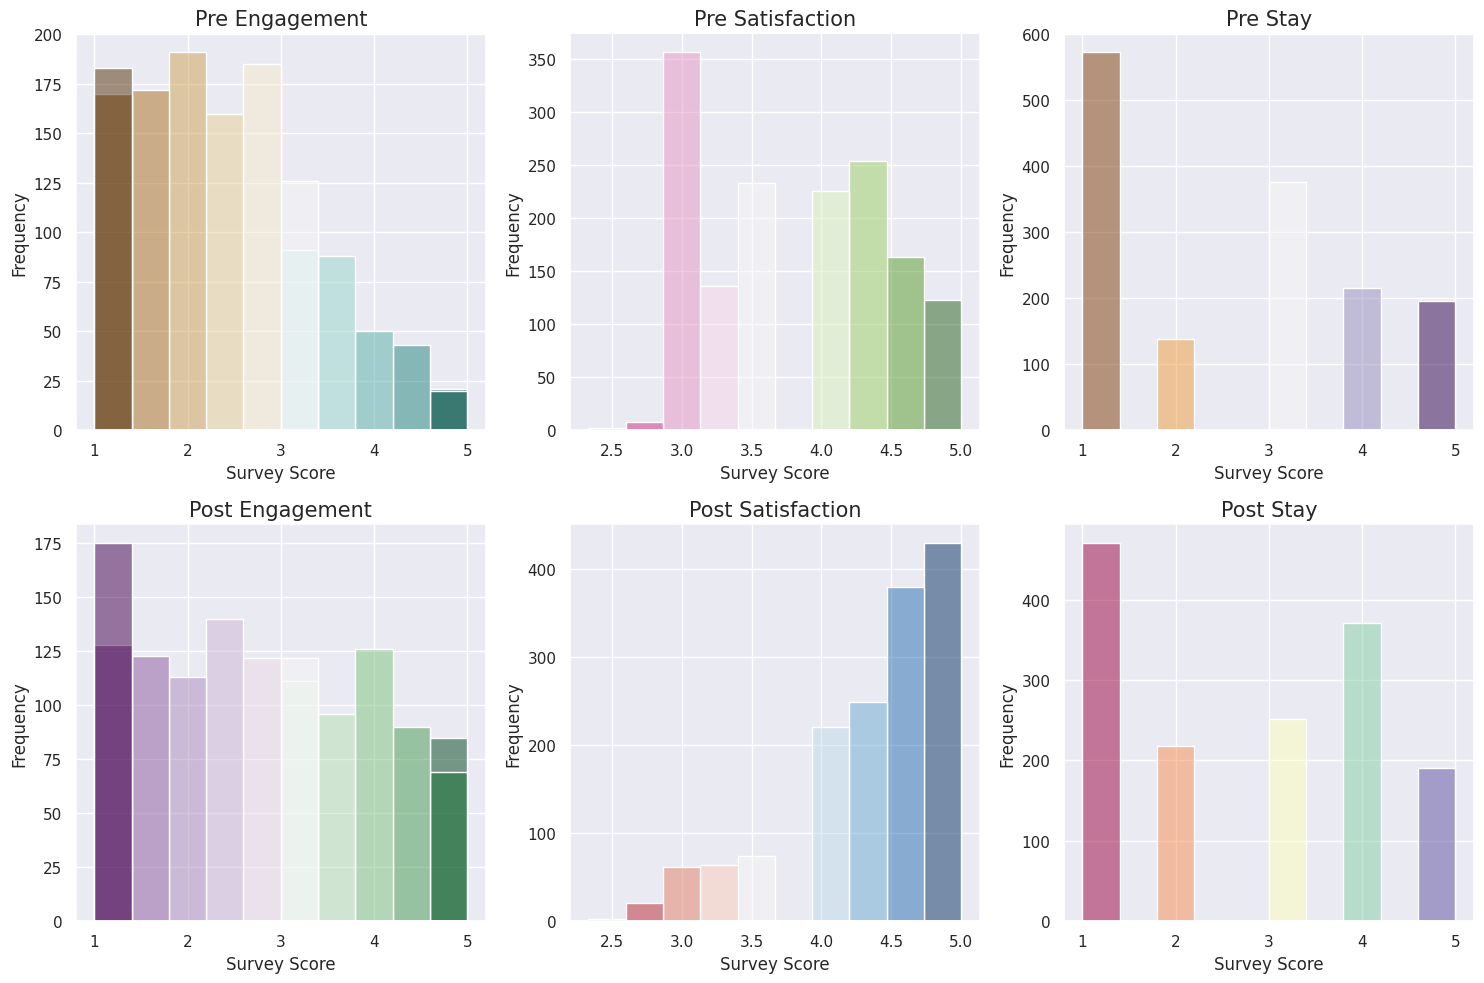

In [114]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

variables = [
    'Pre Engagement',
    'Pre Satisfaction',
    'Pre Stay',
    'Post Engagement',
    'Post Satisfaction',
    'Post Stay']

palettes = ['BrBG', 'PiYG', 'PuOr', 'PRGn', 'RdBu', 'Spectral']

for ax, variable, palette in zip(axes.flat, variables, palettes):
    sns.histplot(
        data=df,
        x=variable,
        bins=10,
        hue=variable,
        palette=palette,
        legend=False,
        ax=ax)

    ax.set_title(variable, fontsize=15)
    ax.set_xlabel("Survey Score")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

- Employee engagement: concentrated at the lower scores (1-3) before and after intervention. There are slightly higher scores between 3-5 post-intervention.
- Employee satisfaction: there's a clear improvement in satisfaction with a cluster at 4-5.
- Intention to stay: shifts towards higher scores, specifically at 4. Many still said 1 so it might show lack of change.

Impact: post-intervention results suggest improvements in employee satisfaction, although it's not consistent across employees.

In [115]:
for intervention, pre, post, title in interventions:
    group = df[df[intervention] == 1]

    print(title)
    print("Pre:", round(group[pre].mean(), 2))
    print("Post:", round(group[post].mean(), 2))
    print("Change:", round((group[post] - group[pre]).mean(), 2))
    print()

Sleep
Pre: 6.69
Post: 7.12
Change: 0.42

Exercise
Pre: 23.52
Post: 27.12
Change: 3.6

Smoking
Pre: 14.82
Post: 7.37
Change: -7.45



- Sleep intervention: sleep duration improves following the intervention. Most employees slept 5-7 hours but afterwards it was closer to 7-9 hours.
- Exercise intervention: there's a modest improvement, with more employees working out for 20-40 minutes after.
- Smoking intervention: this is the clearest improvement, with more lower values after the intervention.

Overall Findings: All three interventions show potentially positive behavioral changes, with smoking reduction and increased sleep appearing particularly noticeable.

H₀: Participation in the sleep, exercise, or smoking intervention is not associated with changes in employee satisfaction, engagement, or intention to stay.



Hₐ: Participation in the sleep, exercise, or smoking intervention is associated with changes in employee satisfaction, engagement, or intention to stay.

Hypothesis testing

In [116]:
intervention_columns = [
    'Sleep intervention (Y=1, N=0)',
    'Exercise intervention (Y=1, N=0)',
    'Smoking intervention (Y=1,N=0)']

outcomes = [
    'Engagement Change',
    'Satisfaction Change',
    'Stay Change']

for intervention in intervention_columns:
    for outcome in outcomes:

        participants = df[df[intervention] == 1][outcome].dropna()
        nonparticipants = df[df[intervention] == 0][outcome].dropna()

        t, p = stats.ttest_ind(
            participants,
            nonparticipants,
            equal_var=False)

        print(f"\nResults of {intervention} x {outcome}:")
        print(f"T-statistic: {t:.3f}")
        print(f"P-value: {p:.5f}")

        if p < 0.05:
            print("Reject the null hypothesis.")
        else:
            print("Fail to reject the null hypothesis.")


Results of Sleep intervention (Y=1, N=0) x Engagement Change:
T-statistic: 18.286
P-value: 0.00000
Reject the null hypothesis.

Results of Sleep intervention (Y=1, N=0) x Satisfaction Change:
T-statistic: 32.117
P-value: 0.00000
Reject the null hypothesis.

Results of Sleep intervention (Y=1, N=0) x Stay Change:
T-statistic: 5.546
P-value: 0.00000
Reject the null hypothesis.

Results of Exercise intervention (Y=1, N=0) x Engagement Change:
T-statistic: -3.695
P-value: 0.00023
Reject the null hypothesis.

Results of Exercise intervention (Y=1, N=0) x Satisfaction Change:
T-statistic: 4.434
P-value: 0.00001
Reject the null hypothesis.

Results of Exercise intervention (Y=1, N=0) x Stay Change:
T-statistic: 6.612
P-value: 0.00000
Reject the null hypothesis.

Results of Smoking intervention (Y=1,N=0) x Engagement Change:
T-statistic: 11.216
P-value: 0.00000
Reject the null hypothesis.

Results of Smoking intervention (Y=1,N=0) x Satisfaction Change:
T-statistic: 5.167
P-value: 0.00000
Rej

In [117]:
for intervention in intervention_columns:
    for outcome in outcomes:

        means = df.groupby(intervention)[outcome].mean()

        print(intervention, outcome)
        print("Nonparticipants:", round(means[0], 3))
        print("Participants:", round(means[1], 3))
        print("Difference:", round(means[1] - means[0], 3))
        print()

Sleep intervention (Y=1, N=0) Engagement Change
Nonparticipants: 0.003
Participants: 0.622
Difference: 0.619

Sleep intervention (Y=1, N=0) Satisfaction Change
Nonparticipants: 0.095
Participants: 0.779
Difference: 0.684

Sleep intervention (Y=1, N=0) Stay Change
Nonparticipants: 0.086
Participants: 0.226
Difference: 0.14

Exercise intervention (Y=1, N=0) Engagement Change
Nonparticipants: 0.537
Participants: 0.355
Difference: -0.182

Exercise intervention (Y=1, N=0) Satisfaction Change
Nonparticipants: 0.469
Participants: 0.592
Difference: 0.123

Exercise intervention (Y=1, N=0) Stay Change
Nonparticipants: 0.08
Participants: 0.229
Difference: 0.15

Smoking intervention (Y=1,N=0) Engagement Change
Nonparticipants: 0.313
Participants: 1.297
Difference: 0.984

Smoking intervention (Y=1,N=0) Satisfaction Change
Nonparticipants: 0.531
Participants: 0.718
Difference: 0.186

Smoking intervention (Y=1,N=0) Stay Change
Nonparticipants: 0.179
Participants: 0.185
Difference: 0.006



8 out of 9 statistical tests are significant, meaning there's evidence to reject the null hypothesis in those

What to do from here?
- prioritize sleep interventions
- reevaluate exercise interventions
- improve smokjing interventions
- investigate employee differences
- assess long-term effectiveness

Machine learning

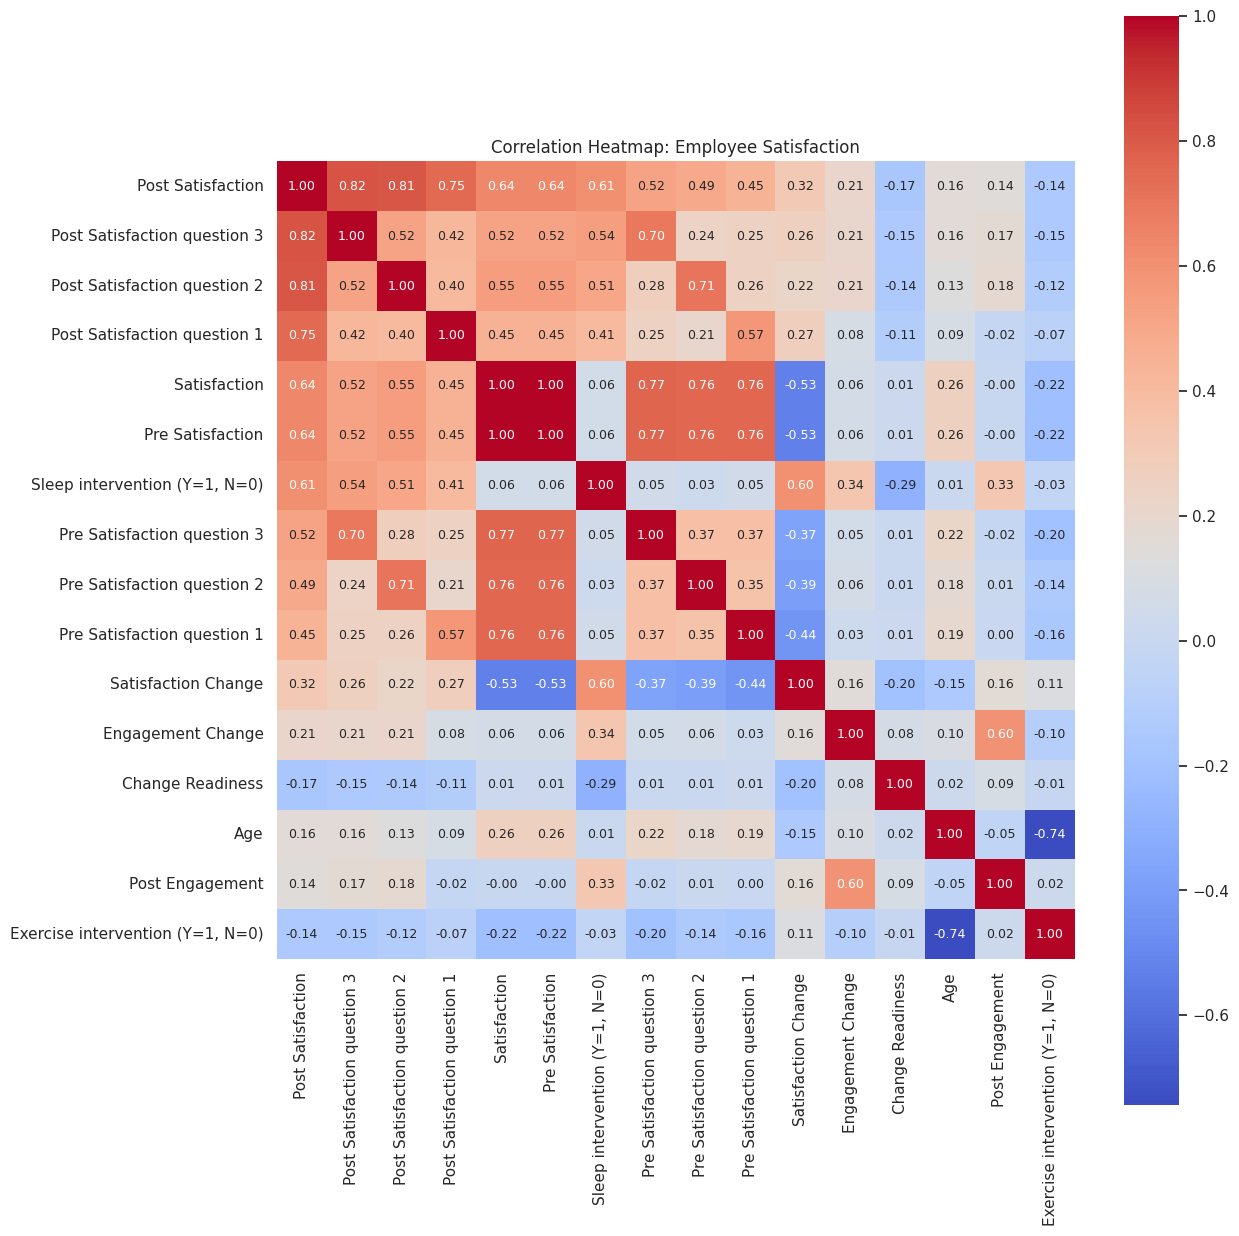

In [118]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

f, ax = plt.subplots(figsize=(13, 13))

corrmat = df.select_dtypes(include='number').corr()

k = 16  # Number of variables for heatmap

cols = corrmat['Post Satisfaction'].abs().nlargest(k).index

cm = df[cols].corr()

sns.set(font_scale=1.0)

hm = sns.heatmap(
    cm,
    cbar=True,
    annot=True,
    square=True,
    fmt='.2f',
    cmap='coolwarm',
    annot_kws={'size': 9},
    ax=ax)

plt.title("Correlation Heatmap: Employee Satisfaction")
plt.tight_layout()
plt.show()

- Sleep intervention has a strong positive correlation with post-intervention satisfaction (r = 0.61)
- Pre- and post-intervention satisfaction are positively correlated (r = 0.64)
- Sleep intervention is positively correlated with satisfaction improvement (r = 0.60
- Exercise intervention has a weak negative correlation with post-intervention satisfaction (r = -0.14)
- Change readiness has a weak negative correlation with post-intervention satisfaction (r = -0.17

Preprocessing


In [119]:
df['High Stay'] = (df['Post: Intention to Stay'] >= 4).astype(int)

y = df['High Stay']

X = df.drop(columns=[
    'High Stay',
    'Post: Intention to Stay',
    'Post Stay',
    'Intention to Stay',
    'Pre Stay',
    'Stay Change',
    'Engagement Change',
    'Satisfaction Change',
    'age_range',
    'tenure_range',
    'Employee ID',
    'Last_name',
    'Start Date',
    'First_name'], errors='ignore')

X = X.loc[:, ~X.columns.str.startswith('Post')]
# Confirm all remaining fields were collected before outcome measurement
X = X.drop(columns=['First_name'], errors='ignore')

X = pd.get_dummies(X, drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=0,
    stratify=y)

imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X.columns,
    index=X_train.index)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X.columns,
    index=X_test.index)

Train/test split

In [120]:
DTree = DecisionTreeClassifier(random_state=0)

DTree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=0)

In [121]:
print("Decision Tree Accuracy:", DTree.score(X_test, y_test))

Decision Tree Accuracy: 0.8233333333333334


In [122]:
print("Baseline Accuracy:", y_test.value_counts(normalize=True).max())

Baseline Accuracy: 0.6266666666666667


In [123]:
RFC = RandomForestClassifier(
    n_estimators=150,
    random_state=0
)

RFC.fit(X_train, y_train)

print("Random Forest Accuracy:", RFC.score(X_test, y_test))

Random Forest Accuracy: 0.85


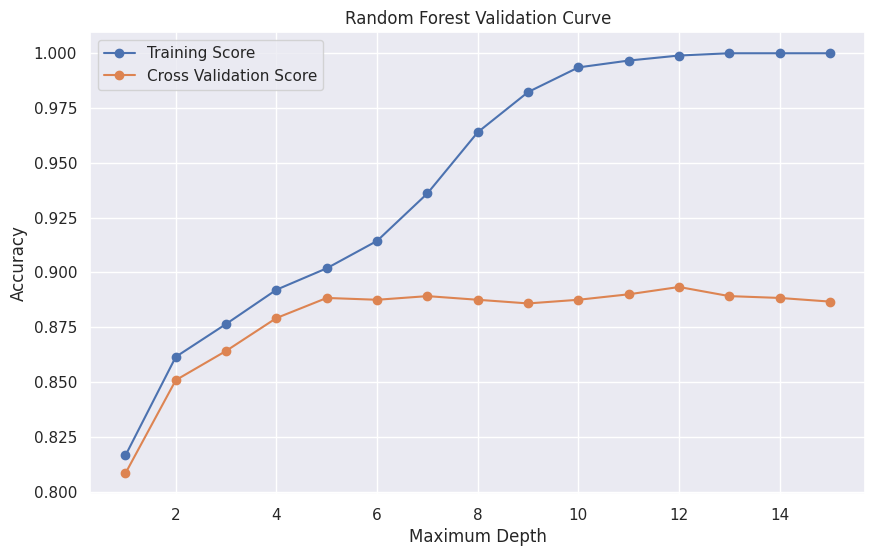

In [124]:
depths = np.arange(1, 16)

train_scores, val_scores = validation_curve(
    RandomForestClassifier(
        n_estimators=150,
        random_state=0
    ),
    X_train,
    y_train,
    param_name="max_depth",
    param_range=depths,
    cv=5,
    scoring="accuracy")

plt.figure(figsize=(10, 6))

plt.plot(
    depths,
    train_scores.mean(axis=1),
    label="Training Score",
    marker='o')

plt.plot(
    depths,
    val_scores.mean(axis=1),
    label="Cross Validation Score",
    marker='o')

plt.title("Random Forest Validation Curve")
plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [125]:
best_depth = depths[val_scores.mean(axis=1).argmax()]

RFC = RandomForestClassifier(
    max_depth=int(best_depth),
    n_estimators=150,
    random_state=0)

RFC.fit(X_train, y_train)

print("Tuned Random Forest Accuracy:", RFC.score(X_test, y_test))

Tuned Random Forest Accuracy: 0.86


In [126]:
print("Decision Tree")
print(classification_report(y_test, DTree.predict(X_test)))

print("Random Forest")
print(classification_report(y_test, RFC.predict(X_test)))

Decision Tree
              precision    recall  f1-score   support

           0       0.86      0.85      0.86       188
           1       0.76      0.78      0.77       112

    accuracy                           0.82       300
   macro avg       0.81      0.81      0.81       300
weighted avg       0.82      0.82      0.82       300

Random Forest
              precision    recall  f1-score   support

           0       0.86      0.93      0.89       188
           1       0.86      0.74      0.80       112

    accuracy                           0.86       300
   macro avg       0.86      0.84      0.85       300
weighted avg       0.86      0.86      0.86       300



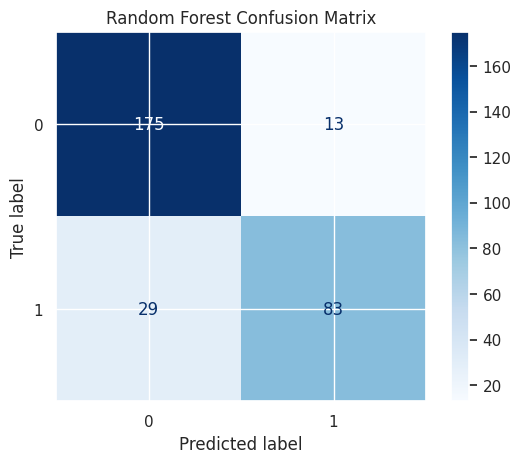

In [127]:
ConfusionMatrixDisplay.from_estimator(
    RFC,
    X_test,
    y_test,
    cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.show()

<Figure size 1000x800 with 0 Axes>

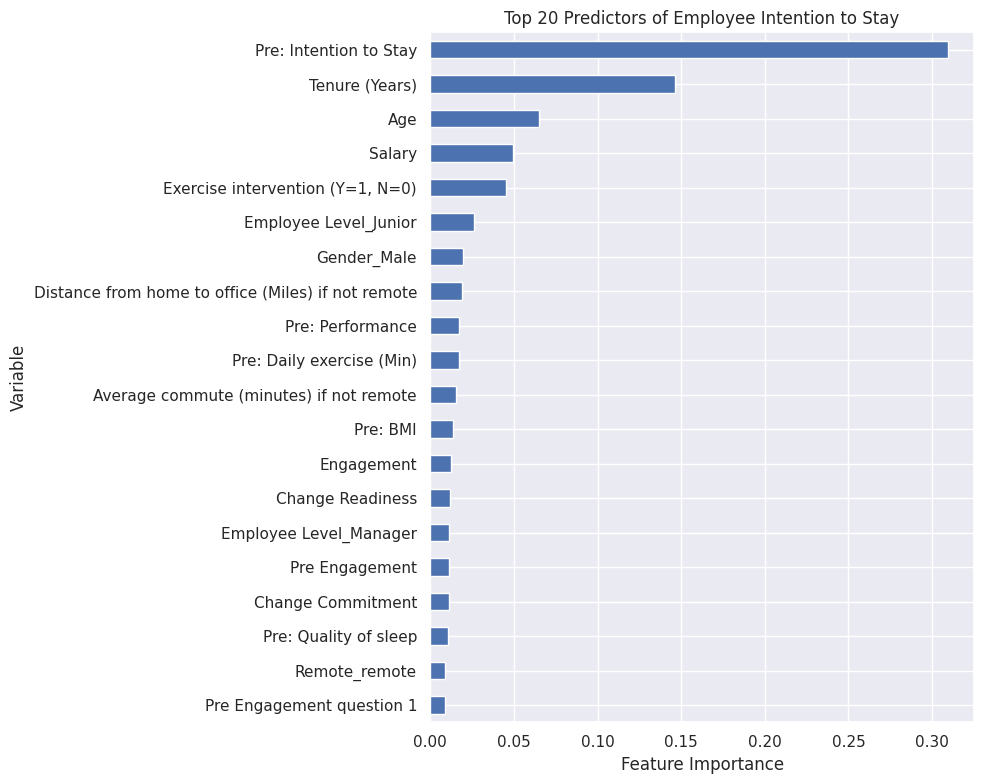

In [128]:
feat_imp = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': RFC.feature_importances_})

feat_imp = (
    feat_imp.sort_values('Importance', ascending=False)
    .set_index('Feature')
    .head(20))

fig = plt.figure(figsize=(10, 8))

feat_imp.sort_values('Importance').plot(
    kind='barh',
    legend=False,
    figsize=(10, 8))

plt.title("Top 20 Predictors of Employee Intention to Stay")
plt.xlabel("Feature Importance")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

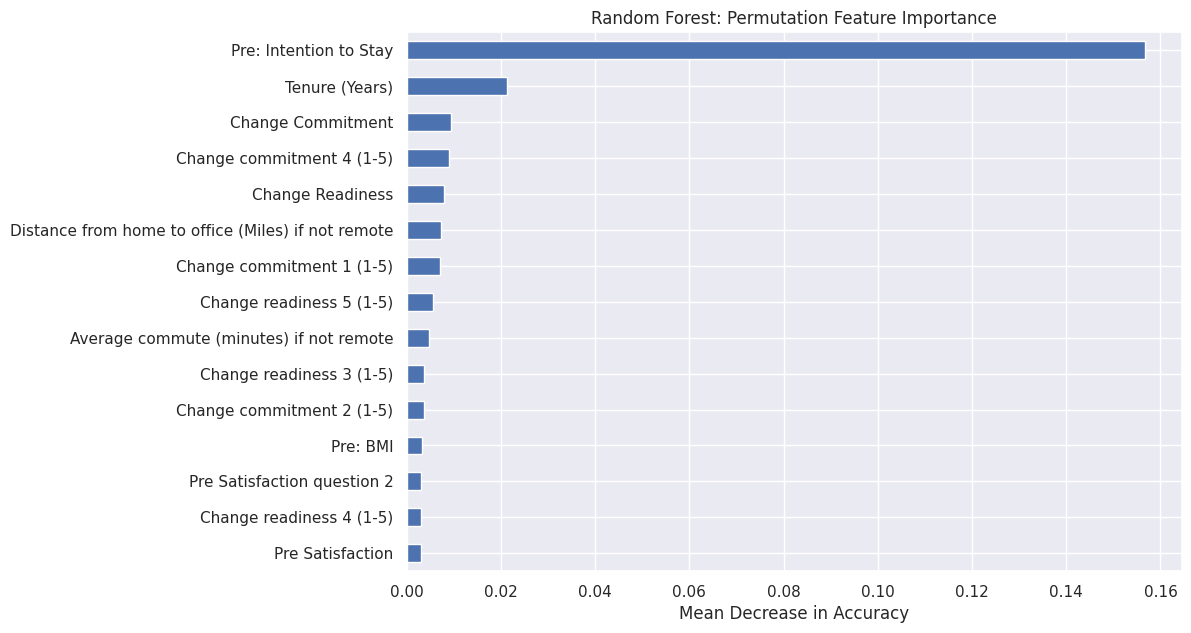

In [129]:
perm = permutation_importance(
    RFC,
    X_test,
    y_test,
    n_repeats=10,
    random_state=0,
    scoring='accuracy')

importance = pd.Series(
    perm.importances_mean,
    index=X_test.columns)

importance.sort_values().tail(15).plot(
    kind='barh',
    figsize=(10, 7))

plt.title("Random Forest: Permutation Feature Importance")
plt.xlabel("Mean Decrease in Accuracy")
plt.show()

In [130]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Remove the baseline retention score
X_train_no_stay = X_train.drop(
    columns=['Pre: Intention to Stay'],
    errors='ignore')

X_test_no_stay = X_test.drop(
    columns=['Pre: Intention to Stay'],
    errors='ignore')

RFC_no_stay = RandomForestClassifier(
    max_depth=RFC.max_depth,
    n_estimators=150,
    random_state=0)

RFC_no_stay.fit(X_train_no_stay, y_train)

print("Original Model:", round(RFC.score(X_test, y_test), 3))
print("Without Baseline Stay:", round(RFC_no_stay.score(X_test_no_stay, y_test), 3))

Original Model: 0.86
Without Baseline Stay: 0.8


In [131]:
results = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Accuracy': [
        DTree.score(X_test, y_test),
        RFC.score(X_test, y_test)]})

print(results)

           Model  Accuracy
0  Decision Tree  0.823333
1  Random Forest  0.860000


**Model comparison:** Interpret the accuracy table generated immediately above. Scores may differ after preprocessing changes.

Evaluation

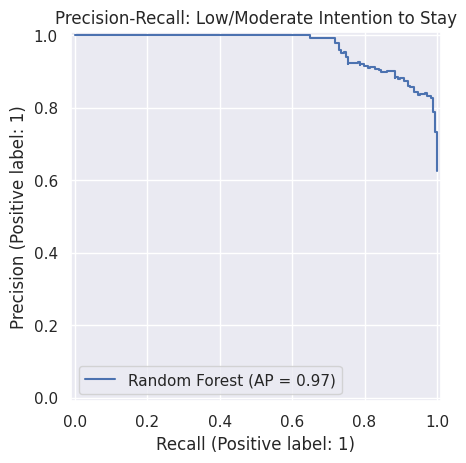

In [132]:
y_risk = (y_test == 0).astype(int)

risk_probability = RFC.predict_proba(X_test)[:, 0]

PrecisionRecallDisplay.from_predictions(
    y_risk,
    risk_probability,
    name="Random Forest")

plt.title("Precision-Recall: Low/Moderate Intention to Stay")
plt.show()

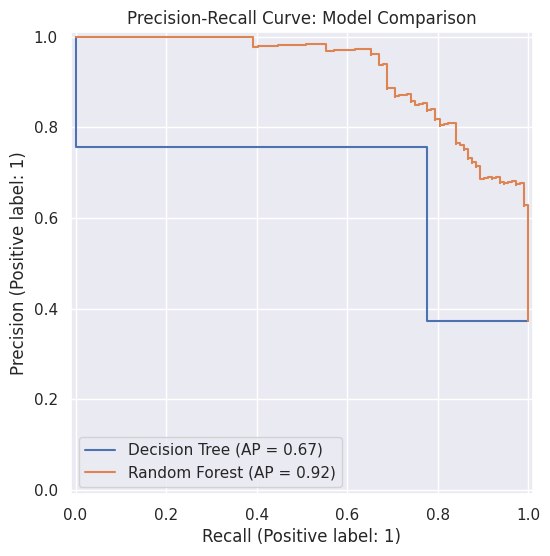

In [133]:
fig, ax = plt.subplots(figsize=(10, 6))

PrecisionRecallDisplay.from_estimator(
    DTree, X_test, y_test,
    ax=ax, name="Decision Tree")

PrecisionRecallDisplay.from_estimator(
    RFC, X_test, y_test,
    ax=ax, name="Random Forest")

plt.title("Precision-Recall Curve: Model Comparison")
plt.show()

One important consideration: Your precision-recall plots use Class 1 (high intention to stay) as the positive class. Since BSR is interested in employee retention risks, evaluating Class 0 (low/moderate intention to stay) as the positive class would provide an additional, more business-relevant assessment.

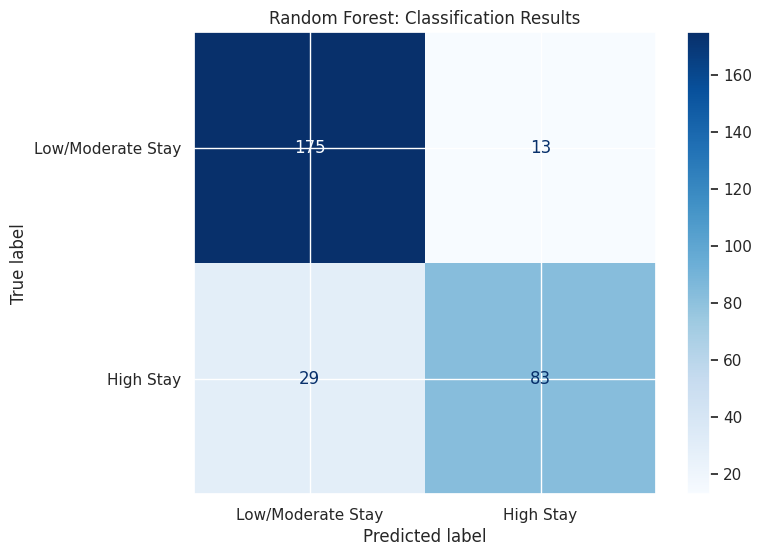

In [134]:
fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_estimator(
    RFC,
    X_test,
    y_test,
    display_labels=["Low/Moderate Stay", "High Stay"],
    cmap="Blues",
    ax=ax)

plt.title("Random Forest: Classification Results")
plt.show()

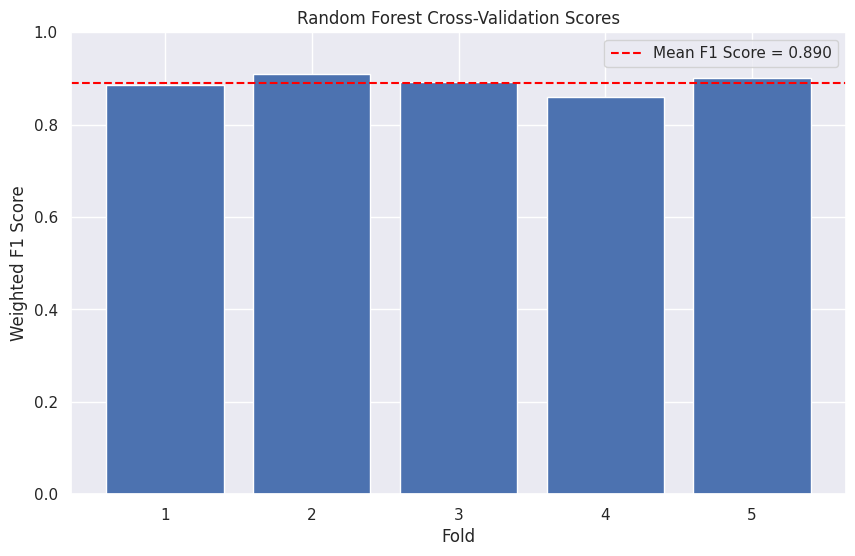

In [135]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=0)

scores = cross_val_score(
    clone(RFC),
    X_train,
    y_train,
    cv=cv,
    scoring='f1_weighted')

plt.figure(figsize=(10, 6))

plt.bar(range(1, 6), scores)

plt.axhline(
    scores.mean(),
    color='red',
    linestyle='--',
    label=f'Mean F1 Score = {scores.mean():.3f}')

plt.title("Random Forest Cross-Validation Scores")
plt.xlabel("Fold")
plt.ylabel("Weighted F1 Score")
plt.ylim(0, 1)
plt.legend()
plt.show()

In [136]:
dt_scores = cross_val_score(
    clone(DTree), X_train, y_train,
    cv=cv, scoring='f1_weighted'
)

rf_scores = cross_val_score(
    clone(RFC), X_train, y_train,
    cv=cv, scoring='f1_weighted'
)

print("Decision Tree Mean F1:", round(dt_scores.mean(), 3))
print("Random Forest Mean F1:", round(rf_scores.mean(), 3))

Decision Tree Mean F1: 0.859
Random Forest Mean F1: 0.89


Conclusion

This machine learning analysis provides a strong foundation for predicting employee intention to stay based on demographic characteristics, workplace factors, and wellness interventions. The Random Forest model demonstrated the strongest predictive performance, achieving 86% accuracy, an average precision of 0.93, and consistent cross-validation results. While these findings suggest that machine learning can effectively identify patterns in employee retention intentions, further analysis is necessary to determine the long-term effectiveness of wellness interventions and translate these predictions into actionable business recommendations.